# Explore the three source files

This notebook is the Week 1 pass over the raw files, before the warehouse and the models. It checks shape, types, missing values, and a few pictures. The five written observations are below and are recomputed by the code cells.

All three datasets are synthetic or simulated by their authors. Say that when you talk about the project.


## Five observations

1. **The Azure telemetry is a complete hourly grid.** 100 machines, 8,761 hours each, 876,100 rows, from 2015-01-01 06:00 through 2016-01-01 06:00. No nulls. No duplicate machine-hours. The gap between rows is always one hour, which is why a 24-row rolling window is a 24-hour window.

2. **Failures are rare and uneven.** 761 failure events: comp2 259, comp1 192, comp4 179, comp3 131. Marking only the failure hour would make the positive class a fraction of a percent of machine-hours. The classifier instead labels the 24 hours before a failure, and it is scored with precision, recall, and PR-AUC rather than accuracy.

3. **Maintenance starts before the sensors do.** 3,286 replacement rows, every one of them timestamped at 06:00, and the log opens on 2014-06-01. Every machine has each of the four components replaced at least once before telemetry starts, so "hours since replacement" is observed on day one of 2015 rather than censored.

4. **Errors are the noisy middle layer.** 3,919 error events. error1 is the most common (1,010) and error5 the least (356). They are features. Failures are labels. Mixing those two up would leak the answer into the model.

5. **The other two files are different machines, kept for the modeling proof.** C-MAPSS FD001 is 100 engines run to failure (20,631 cycles, life from 128 to 362 cycles, median 199). Seven channels never move on the training engines (`op3`, `s1`, `s5`, `s10`, `s16`, `s18`, `s19`) and are dropped from that model. AI4I is 10,000 rows and 3.39% failures (339). The failure modes are rarer still: TWF 46, HDF 115, PWF 95, OSF 98, RNF 19. RNF is defined as random, so it is not a target.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RAW = Path("../data/raw")
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (8, 3.4)


In [2]:
telemetry = pd.read_csv(RAW / "azure" / "PdM_telemetry.csv", parse_dates=["datetime"])
errors = pd.read_csv(RAW / "azure" / "PdM_errors.csv", parse_dates=["datetime"])
maint = pd.read_csv(RAW / "azure" / "PdM_maint.csv", parse_dates=["datetime"])
failures = pd.read_csv(RAW / "azure" / "PdM_failures.csv", parse_dates=["datetime"])
machines = pd.read_csv(RAW / "azure" / "PdM_machines.csv")

for name, frame in [("telemetry", telemetry), ("errors", errors), ("maint", maint), ("failures", failures), ("machines", machines)]:
    print(f"\n== {name} {frame.shape} ==")
    print(frame.dtypes.to_string())
    print("nulls", int(frame.isna().sum().sum()))
print("\ntelemetry describe")
print(telemetry.describe().round(2))



== telemetry (876100, 6) ==
datetime     datetime64[us]
machineID             int64
volt                float64
rotate              float64
pressure            float64
vibration           float64
nulls 0

== errors (3919, 3) ==
datetime     datetime64[us]
machineID             int64
errorID                 str
nulls 0

== maint (3286, 3) ==
datetime     datetime64[us]
machineID             int64
comp                    str
nulls 0

== failures (761, 3) ==
datetime     datetime64[us]
machineID             int64
failure                 str
nulls 0

== machines (100, 3) ==
machineID    int64
model          str
age          int64
nulls 0

telemetry describe
                         datetime  machineID       volt     rotate   pressure  \
count                      876100  876100.00  876100.00  876100.00  876100.00   
mean   2015-07-02 17:59:59.999999      50.50     170.78     446.61     100.86   
min           2015-01-01 06:00:00       1.00      97.33     138.43      51.24   
25%          

In [3]:
ordered = telemetry.sort_values(["machineID", "datetime"])
gaps = ordered.groupby("machineID")["datetime"].diff().dropna().dt.total_seconds()
print("machines", telemetry.machineID.nunique())
print("rows per machine", sorted(telemetry.groupby("machineID").size().unique()))
print("span", telemetry.datetime.min(), "->", telemetry.datetime.max())
print("unique gaps (seconds)", sorted(gaps.unique()))
print("duplicate machine-hours", int(telemetry.duplicated(["datetime", "machineID"]).sum()))


machines 100
rows per machine [np.int64(8761)]
span 2015-01-01 06:00:00 -> 2016-01-01 06:00:00
unique gaps (seconds) [np.float64(3600.0)]
duplicate machine-hours 0


failure
comp2    259
comp1    192
comp4    179
comp3    131
Name: count, dtype: int64


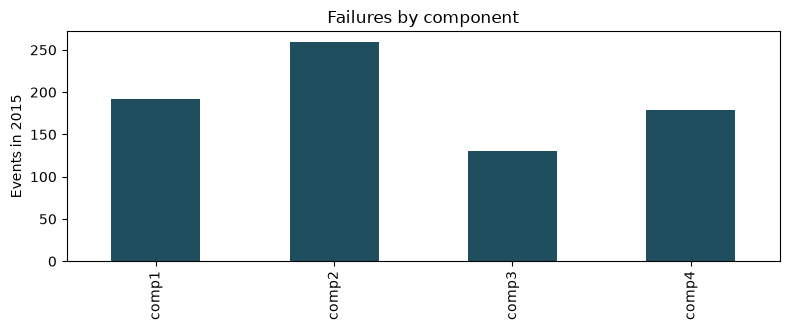

maintenance span 2014-06-01 06:00:00 -> 2016-01-01 06:00:00 rows 3286
maintenance hours [np.int32(6)]
pre-2015 machine-component pairs 400 of 400
errorID
error1    1010
error2     988
error3     838
error4     727
error5     356
Name: count, dtype: int64


In [4]:
print(failures.failure.value_counts())
ax = failures.failure.value_counts().sort_index().plot(kind="bar", color="#1f4e5f", title="Failures by component")
ax.set_xlabel("")
ax.set_ylabel("Events in 2015")
plt.tight_layout()
plt.show()
print("maintenance span", maint.datetime.min(), "->", maint.datetime.max(), "rows", len(maint))
print("maintenance hours", sorted(maint.datetime.dt.hour.unique()))
early = maint[maint.datetime < "2015-01-01"]
print("pre-2015 machine-component pairs", early.groupby(["machineID", "comp"]).ngroups, "of", 400)
print(errors.errorID.value_counts())


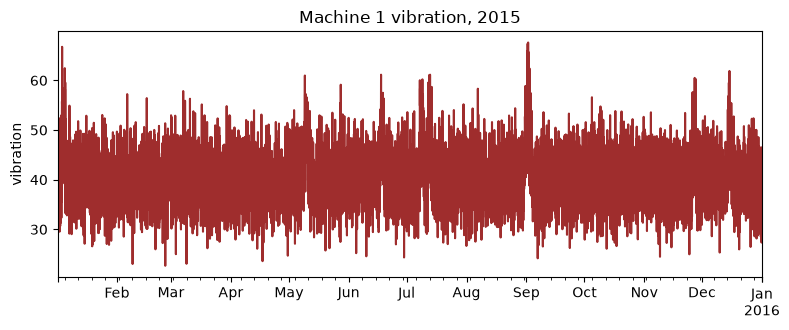

In [5]:
machine = telemetry[telemetry.machineID == 1]
ax = machine.plot(x="datetime", y="vibration", color="#9f2d2d", legend=False, title="Machine 1 vibration, 2015")
ax.set_xlabel("")
ax.set_ylabel("vibration")
plt.tight_layout()
plt.show()


engines 100 rows 20631
life min/median/max 128 199.0 362
constant channels ['op3', 's1', 's5', 's10', 's16', 's18', 's19']


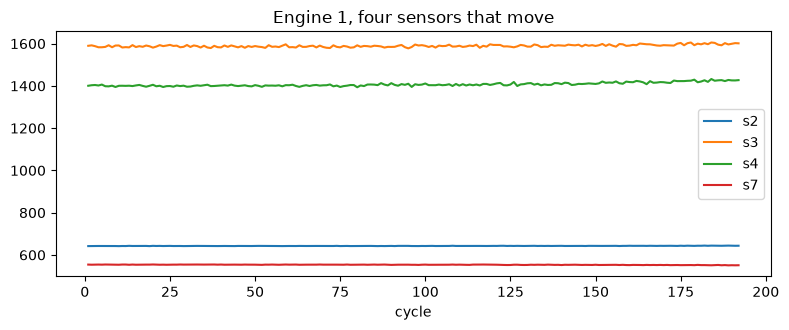

In [6]:
cmapss_cols = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
train = pd.read_csv(RAW / "cmapss" / "train_FD001.txt", sep=r"\s+", header=None, names=cmapss_cols)
life = train.groupby("unit").cycle.max()
constant = [c for c in cmapss_cols if c not in ("unit", "cycle") and train[c].std(ddof=0) < 1e-8]
print("engines", train.unit.nunique(), "rows", len(train))
print("life min/median/max", int(life.min()), float(life.median()), int(life.max()))
print("constant channels", constant)
engine = train[train.unit == 1]
ax = engine.plot(x="cycle", y=["s2", "s3", "s4", "s7"], title="Engine 1, four sensors that move")
ax.set_xlabel("cycle")
plt.tight_layout()
plt.show()


In [7]:
ai4i = pd.read_csv(RAW / "ai4i" / "ai4i2020.csv")
print(ai4i.shape)
print("failure rate", float(ai4i["Machine failure"].mean()))
print(ai4i[["TWF", "HDF", "PWF", "OSF", "RNF"]].sum())
print(ai4i.isna().sum().sum(), "nulls")


(10000, 14)
failure rate 0.0339
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64
0 nulls
